<a href="https://colab.research.google.com/github/JFish72/CSC-349-Machine-Learning-/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task One:**
* To begin this project, I first had to find the dataset on the UCI Machine Learning Repository. I struggled to find the correct dataset at first since most of the downloads I found were in unfamiliar ZIP files with .tar.Z files in them. After using Kaggle to find a .CSV file of the diabetes data, I downloaded the necessary data to my computer and uploaded it directly into Google Colab. Once uploaded, I followed the same normal procedure of putting the data into a pandas DataFrame to further manipulate and inspect the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/diabetes.csv")

**Task Two:**
*   Now that our data is in a pandas DataFrame we can do what is one of most important steps of creating a ML model which is the inspection of our data. In this task I used our standard three inspection functions (head(), info(), and describe()).
*   After execution, df.head() immediately shows us an issue with the data, and that is the recorded values under Insulin being 0. This gives the insight that other columns, as well as Insulin, use zero as a placeholder for an unrecorded value rather than the NaN value. df.info() also supports this assumption, with every column having exactly 768 non-null values. df.describe shows which columns contain unrecorded data, with a minimum of 0. The only column we can assume is somewhat safe from this is pregnancies, as it is possible for someone to not have a pregnancy.



In [2]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


**Task Three:**
*   Now that the implicit missing values have been discovered, we have to replace them with a NaN value so that in later steps we can handle them accordingly. First, it is very important to determine which columns we can accurately say that the value 0 is the result of an unrecorded value. We can assume then that columns such as Glucose, BloodPressure, SkinThickness, Insulin, and BMI have the value 0 as an implicit missing value since, scientifically speaking it is not possible to record 0 for any of these columns. For pregnancies, we are unable to say for certain whether the value is accurate at having 0 pregnancies or if the value is simply unrecorded. For now, I have decided to not adjust this column.  
*   After executing the first block of code, we can see how df.info() produces a much different result and shows us just how many unrecorded values there are in the dataset.
*   Now that these unrecorded values have been both found and replaced with the correct NaN value, we are going to handle them with the SimpleImputer, just like we've done in past projects. I am going to include this in my preprocessing pipeline.
*   Therefore, the SimpleImputer will be used in my task four section rather than here in task three.

In [5]:
missing_values = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df[missing_values] = df[missing_values].replace(0, np.nan)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   763 non-null    float64
 2   BloodPressure             733 non-null    float64
 3   SkinThickness             541 non-null    float64
 4   Insulin                   394 non-null    float64
 5   BMI                       757 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB


**Task Four:**
*   My reason for including the SimpleImputer step and all other preprocessing steps together is to make it easier to reuse in future tasks alongside the pipeline. This serves to create consistency once we begin to create different classifiers and such.
*   Since all of the column types we are using for this dataset are numerical, I did not need to use similar tools such as OneHotEncoder like I have had to in past assignments.
*   Proper scaling is very important in this assignment as well, since the numerical data and their ranges are quite different. For example, comparing Pregnancies and Insulin. Missing this could have a negative effect on the results our SVC will later give us.
*   I once again chose to use the StandardScaler over the MinMaxScaler since I am more comfortable with using the StandardScaler and how it operates.


In [6]:
from pandas.core.arrays import numeric
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

numeric_features = X.columns.tolist()

numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])

preprocessor = ColumnTransformer(transformers=[("num", numeric_transformer, numeric_features)])



**Task Five:**
*   This task requires the use of ensemble learning which will use the results of our logistic regression model, SVC model, and our decision tree classifier to improve the overall model. In this scenario, I am comparing the hard voting classifier style for ensemble learning, which combines the predicted class labels from the seperate model and chooses the class which the majority votes for, to the soft voting classifier that combines the predicted class probabilites, calculates the average probability for each class, and then chooses the class with the highest average probability. Soft voting considers the confidence of the models while hard voting uses just the class predictions.
*   To compare the different styles of ensemble learning I want to use a bar chart, as I think they present differences in results the clearest.

In [8]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

logistic_regression = LogisticRegression(max_iter = 1000, random_state = 42)
svc = SVC(probability = True, random_state = 42)
decision_tree = DecisionTreeClassifier(random_state = 42)

hard_model = Pipeline([("preprocessor", preprocessor), ("classifier", VotingClassifier
 (estimators=[("lr", logistic_regression), ("svc", svc), ("dt", decision_tree)], voting="hard"))])
soft_model = Pipeline([("preprocessor", preprocessor), ("classifier", VotingClassifier
 (estimators=[("lr", logistic_regression), ("svc", svc), ("dt", decision_tree)], voting="soft"))])

hard_model.fit(X_train, y_train)
soft_model.fit(X_train, y_train)

hard_predictions = hard_model.predict(X_test)
soft_predictions = soft_model.predict(X_test)

hard_model_accuracy = accuracy_score(y_test, hard_predictions)
soft_model_accuracy = accuracy_score(y_test, soft_predictions)

print("Hard Voting Classifier Accuracy:", hard_model_accuracy)
print(classification_report(y_test, hard_predictions))

print("Soft Voting Classifier Accuracy:", soft_model_accuracy)
print(classification_report(y_test, soft_predictions))

Hard Voting Classifier Accuracy: 0.7662337662337663
              precision    recall  f1-score   support

           0       0.81      0.84      0.82        99
           1       0.69      0.64      0.66        55

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.76      0.77      0.76       154

Soft Voting Classifier Accuracy: 0.7337662337662337
              precision    recall  f1-score   support

           0       0.80      0.78      0.79        99
           1       0.62      0.65      0.64        55

    accuracy                           0.73       154
   macro avg       0.71      0.72      0.71       154
weighted avg       0.74      0.73      0.74       154



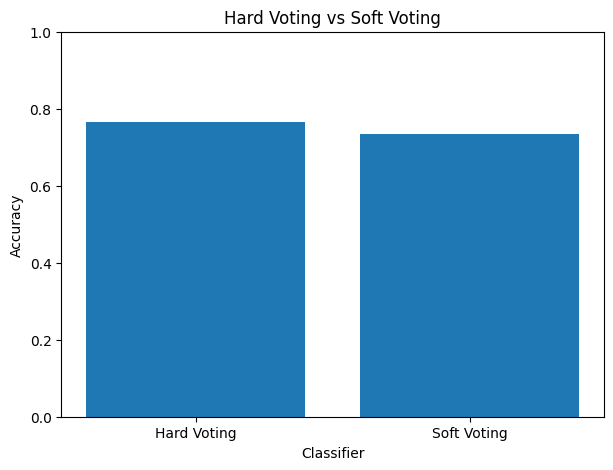

In [9]:
plt.figure(figsize=(7, 5))

plt.bar(["Hard Voting", "Soft Voting"], [hard_model_accuracy, soft_model_accuracy])

plt.title("Hard Voting vs Soft Voting")
plt.xlabel("Classifier")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()

**Task Six:**
*   The bagging classifier in this example will be made by 100 decision trees as its base estimators. For mine, I'm using boot strap sampling which creates training subsets by randomly selecting observations with replacement. Because this method uses replacement, the same observation can appear in the same subset multiple times. Since some observations are naturally excluded, the out-of-bag evaluation picks these and evaulautes the model's performance further.  
*   List item